In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

input_csv = "../data/fraud_capture_mini_project.csv"
raw_df = pd.read_csv(input_csv)


In [2]:
raw_df.info()

raw_df.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   application_id      10000 non-null  str    
 1   application_date    10000 non-null  str    
 2   fraud_score         10000 non-null  int64  
 3   fraud_label         10000 non-null  int64  
 4   application_amount  10000 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 390.8 KB


,application_id,application_date,fraud_score,fraud_label,application_amount
0,APP006253,4/25/25,218,0,2109.40
1,APP004685,3/24/25,516,0,2017.95
2,APP001732,5/3/25,130,0,1800.13
3,APP004743,3/30/25,214,0,2769.69
4,APP004522,6/19/25,686,0,33250.69


### Quality Checks


In [3]:
# Any null values? 
raw_df.isnull().sum()

application_id        0
application_date      0
fraud_score           0
fraud_label           0
application_amount    0
dtype: int64

In [4]:
# Is our application_id unique?
raw_df["application_id"].is_unique

True

In [5]:
# Are any rows exact duplicates?
raw_df.duplicated().sum()

np.int64(0)

In [6]:
# Is fraud_score within the 0-999 range? 
print(raw_df["fraud_score"].max())
print(raw_df["fraud_score"].min())

965
4


In [7]:
# What are the top 10 highest application amounts? 
raw_df["application_amount"].sort_values(ascending=False).head(10)

1821    45000.0
3644    45000.0
8624    45000.0
7556    45000.0
3739    45000.0
8172    45000.0
4858    45000.0
5662    45000.0
5364    45000.0
5283    45000.0
Name: application_amount, dtype: float64

In [8]:
# What are the top 10 highest application amounts? 
raw_df["application_amount"].sort_values(ascending=True).head(10)

9027    300.00
9518    300.00
6831    300.00
3433    300.00
3761    300.00
7185    300.00
8361    300.00
9047    300.00
3073    300.00
5905    307.77
Name: application_amount, dtype: float64

In [9]:
# Look at application_amount by counts
raw_df["application_amount"].value_counts().reset_index().sort_values(by="count", ascending=False).head(10)

,application_amount,count
0,45000.00,17
1,300.00,9
35,1528.46,2
26,2788.63,2
27,3515.42,2
28,8624.09,2
29,6786.14,2
30,3460.18,2
31,4789.33,2
32,2624.55,2


In [10]:
# Confirm we only have values of 0 and 1
raw_df["fraud_label"].value_counts(dropna=False)

fraud_label
0    9798
1     202
Name: count, dtype: int64

In [11]:
# Create new dataframe to clean up 
clean_df = raw_df.copy()

In [12]:
clean_df["is_fraud"] = clean_df["fraud_label"] == 1

In [13]:
clean_df["application_date"] = pd.to_datetime(
            raw_df["application_date"], 
            format="%m/%d/%y"
    )

In [14]:
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   application_id      10000 non-null  str           
 1   application_date    10000 non-null  datetime64[us]
 2   fraud_score         10000 non-null  int64         
 3   fraud_label         10000 non-null  int64         
 4   application_amount  10000 non-null  float64       
 5   is_fraud            10000 non-null  bool          
dtypes: bool(1), datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 400.5 KB


In [15]:
clean_df["fraud_score"].describe()

count    10000.000000
mean       346.439500
std        183.335601
min          4.000000
25%        200.000000
50%        328.000000
75%        475.000000
max        965.000000
Name: fraud_score, dtype: float64

In [16]:
fraud_rate = clean_df["is_fraud"].mean()

In [17]:
print(f"The Baseline Fraud Rate for the total population is: {fraud_rate:.2%}")

The Baseline Fraud Rate for the total population is: 2.02%


In [18]:
# Lets check to see how that compares by month
fraud_by_month = clean_df.groupby(clean_df["application_date"].dt.to_period("M"))["is_fraud"].mean().round(4).reset_index()
print("=== Fraud Rate By Month ===")
fraud_by_month

=== Fraud Rate By Month ===


,application_date,is_fraud
0,2025-01,0.0215
1,2025-02,0.0211
2,2025-03,0.0177
3,2025-04,0.0243
4,2025-05,0.0169
5,2025-06,0.0200


In [19]:
# Lets check to see how that compares by month
by_month_stats = (clean_df.groupby(clean_df["application_date"]
                    .dt.to_period("M"))
                    .agg(application_count = ("application_id", "count"), 
                         fraud_count = ("is_fraud", "sum")
            )
    )


In [20]:
by_month_stats["fraud_rate"] = (by_month_stats["fraud_count"] / by_month_stats["application_count"]).round(4)

In [21]:
print("=== Fraud Rate By Month ===")
by_month_stats

=== Fraud Rate By Month ===


,application_count,fraud_count,fraud_rate
application_date,,,
2025-01,1719,37,0.0215
2025-02,1515,32,0.0211
2025-03,1698,30,0.0177
2025-04,1645,40,0.0243
2025-05,1774,30,0.0169
2025-06,1649,33,0.0200


In [22]:
# Double check application total counts
by_month_stats["application_count"].sum()

np.int64(10000)

In [23]:
# Double check fraud total counts
by_month_stats["fraud_count"].sum()

np.int64(202)

In [24]:
# Lets create a columns of score bins using the fraud_score
performance_table = clean_df.copy()

In [25]:
performance_table["score_bin"] = pd.cut(performance_table["fraud_score"], bins=range(0,1001,50), right=False)

In [26]:
aggregate_table = (performance_table
                        .groupby("score_bin")
                        .agg(applications_per_bin = ("application_id", "count"), 
                             fraud_count_per_bin = ("is_fraud", "sum"))
                        .sort_index(ascending=False)
)

In [27]:
aggregate_table["precision_per_bin"] = (aggregate_table["fraud_count_per_bin"] / aggregate_table["applications_per_bin"]).mul(100)

In [28]:
# To use for recall 
total_fraud = clean_df['is_fraud'].sum()
total_fraud

np.int64(202)

In [29]:
aggregate_table["recall_per_bin"] = (aggregate_table["fraud_count_per_bin"] / total_fraud).mul(100)

In [30]:
# Lets create a cumulative sum column 
aggregate_table["application_count_cumulative"] = (
    aggregate_table["applications_per_bin"].cumsum()
)

In [31]:
aggregate_table["fraud_count_cumulative"] = aggregate_table["fraud_count_per_bin"].cumsum()
aggregate_table

,applications_per_bin,fraud_count_per_bin,precision_per_bin,recall_per_bin,application_count_cumulative,fraud_count_cumulative
score_bin,,,,,,
"[950, 1000)",1,1,100.000000,0.495050,1,1
"[900, 950)",4,0,0.000000,0.000000,5,1
"[850, 900)",33,8,24.242424,3.960396,38,9
"[800, 850)",55,9,16.363636,4.455446,93,18
"[750, 800)",126,12,9.523810,5.940594,219,30
"[700, 750)",176,29,16.477273,14.356436,395,59
"[650, 700)",263,24,9.125475,11.881188,658,83
"[600, 650)",339,25,7.374631,12.376238,997,108
"[550, 600)",527,17,3.225806,8.415842,1524,125


In [32]:
aggregate_table["recall_cumulative"] = aggregate_table["recall_per_bin"].cumsum()

In [33]:
aggregate_table["precision_cumulative"] = (
    aggregate_table["fraud_count_cumulative"]
    / aggregate_table["application_count_cumulative"]
    * 100
)

In [34]:
aggregate_table["false_positive_rate"] = (
    (aggregate_table["application_count_cumulative"]
     - aggregate_table["fraud_count_cumulative"])
    / (len(clean_df) - clean_df["is_fraud"].sum())
    * 100
)

In [35]:
aggregate_table["application_flag_rate"] = (
    aggregate_table["application_count_cumulative"]
    / len(clean_df)
    * 100
)

In [36]:
# Clean the DataFrame to my liking
aggregate_table_clean = aggregate_table[[
                            # "applications_per_bin", 
                            "application_count_cumulative",
                            "application_flag_rate",
                            # "fraud_count_per_bin", 
                            "fraud_count_cumulative", 
                            # "precision_per_bin", 
                            "precision_cumulative",
                           # "recall_per_bin", 
                            "recall_cumulative", 
                            "false_positive_rate"]]

aggregate_table_clean

,application_count_cumulative,application_flag_rate,fraud_count_cumulative,precision_cumulative,recall_cumulative,false_positive_rate
score_bin,,,,,,
"[950, 1000)",1,0.01,1,100.000000,0.495050,0.000000
"[900, 950)",5,0.05,1,20.000000,0.495050,0.040825
"[850, 900)",38,0.38,9,23.684211,4.455446,0.295979
"[800, 850)",93,0.93,18,19.354839,8.910891,0.765462
"[750, 800)",219,2.19,30,13.698630,14.851485,1.928965
"[700, 750)",395,3.95,59,14.936709,29.207921,3.429271
"[650, 700)",658,6.58,83,12.613982,41.089109,5.868545
"[600, 650)",997,9.97,108,10.832497,53.465347,9.073280
"[550, 600)",1524,15.24,125,8.202100,61.881188,14.278424


In [37]:
# Create smaller DataFrame to use for graph
for_visuals = aggregate_table_clean.iloc[[3, 5, 7]]
for_visuals

,application_count_cumulative,application_flag_rate,fraud_count_cumulative,precision_cumulative,recall_cumulative,false_positive_rate
score_bin,,,,,,
"[800, 850)",93,0.93,18,19.354839,8.910891,0.765462
"[700, 750)",395,3.95,59,14.936709,29.207921,3.429271
"[600, 650)",997,9.97,108,10.832497,53.465347,9.073280


In [40]:
monthly_reviews = (
    clean_df.assign(flagged=clean_df["fraud_score"].ge(600))
    .groupby(clean_df["application_date"].dt.to_period("M"))
    ["flagged"].sum()
)

print(monthly_reviews)
print(f"\nHighest monthly review volume: {monthly_reviews.max()}")
print(f"Within capacity every month: {monthly_reviews.le(500).all()}")

application_date
2025-01    166
2025-02    151
2025-03    156
2025-04    187
2025-05    178
2025-06    159
Freq: M, Name: flagged, dtype: int64

Highest monthly review volume: 187
Within capacity every month: True


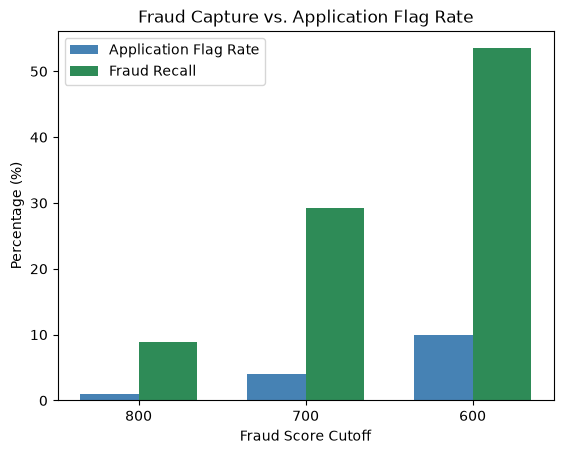

In [38]:
x = np.arange(len(for_visuals))
width = 0.35

plt.bar(
    x - width/2,
    for_visuals["application_flag_rate"],
    width,
    label="Application Flag Rate",
    color="steelblue"
)

plt.bar(
    x + width/2,
    for_visuals["recall_cumulative"],
    width,
    label="Fraud Recall",
    color="seagreen"
)

plt.xticks(x, ["800", "700", "600"])
plt.xlabel("Fraud Score Cutoff")
plt.ylabel("Percentage (%)")
plt.title("Fraud Capture vs. Application Flag Rate")
plt.legend()

plt.show()

### Recommendation: Evaluate a Fraud Score Cutoff of 600

For the 10,000 applications submitted from January through June 2025, a review rule of **fraud score ≥600** would flag **997 applications (9.97%)**, including **108 labeled fraud cases**. This represents **10.83% precision** and **53.47% fraud recall**.

Review volume averages **166 applications per month**, ranging from **151 to 187**. Every observed month falls below the team’s capacity of **500 reviews per month**.

| Score cutoff | Applications flagged | Labeled fraud identified | Precision | Fraud recall |
|---|---:|---:|---:|---:|
| ≥600 | 997 | 108 | 10.83% | 53.47% |
| ≥700 | 395 | 59 | 14.94% | 29.21% |
| ≥800 | 93 | 18 | 19.35% | 8.91% |

*Counts cover the full six-month period.*

Among these three options, **600 identifies the most labeled fraud while remaining within capacity in every observed month**. Compared with 700, it requires **602 additional reviews** to identify **49 additional labeled fraud cases**.

I recommend evaluating 600 as a starting cutoff. Before implementation, assess review costs, customer friction, and the effectiveness of intervention. Lower cutoffs should also be evaluated before selecting an optimal threshold.

These retrospective results show identification opportunity; they do not establish that fraud or losses would have been prevented. Future monthly review volumes may differ.